# ДЗ2 — дополнительное задание: Feature Engineering

## 1. Цель дополнительного задания

Улучшить бинарный прогноз наличия осадков в Оренбурге за счёт календарных признаков и лагов категорий осадков. Цель `target=1` означает, что в прогнозируемый день осадки есть (`precipitation_sum > 0 мм`), `target=0` — осадков нет. Интенсивность осадков не является целевой переменной.

Горизонт сохраняется как в основном ДЗ2: прогноз на следующий день, one-step-ahead. Для дня `t` доступны только наблюдения до `t−1`.


## 2. Исходные данные

Используется исходный CSV Open-Meteo для Оренбурга (суточная сумма осадков в миллиметрах), тот же, что в ДЗ2. Сначала проверяются дубликаты, пропуски и ежедневная регулярность ряда.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_PATH = Path("orenburg_weather_2020_2025.csv")
raw = pd.read_csv(DATA_PATH, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
assert raw["date"].is_unique
assert raw["precipitation_sum"].notna().all()
expected = pd.date_range(raw.date.min(), raw.date.max(), freq="D")
assert raw.date.equals(pd.Series(expected, name="date"))
print(f"Период: {raw.date.min():%d.%m.%Y} — {raw.date.max():%d.%m.%Y}; наблюдений: {len(raw)}")
print("Шаг ряда: 1 день; пропусков и повторов дат нет.")
print(f"Единицы precipitation_sum: мм/сутки; нулевых дней: {(raw.precipitation_sum == 0).sum()}")


Период: 01.01.2020 — 31.12.2025; наблюдений: 2192
Шаг ряда: 1 день; пропусков и повторов дат нет.
Единицы precipitation_sum: мм/сутки; нулевых дней: 1220


## 3. Календарные признаки

Из даты извлекаются день, месяц, год, день недели и день года. Для сезонности добавлены синус и косинус дня года: они позволяют модели считать соседние дни года близкими и корректно замыкают декабрь с январём. Числовые признаки стандартизуются по train; параметры стандартизации не оцениваются по validation/test.


## 4. Категоризация количества осадков

`precipitation_sum` — суточная сумма в миллиметрах. Фиксированные границы: категория 0 — ровно 0 мм; 1 — `(0; 2.5]` мм (небольшие); 2 — `(2.5; 7.5]` мм (средние); 3 — `>7.5` мм (сильные). Порог 2.5/7.5 мм/сутки согласуется с распространёнными порогами интенсивности дождя 2.5 и 7.6 мм; округление до 7.5 обусловлено точностью исходного дневного ряда. Границы заданы до разделения и не подбираются на тесте. Категория используется только как исторический признак, а цель остаётся бинарной.


In [2]:
# Фиксированные пороги в мм/сутки; тестовая выборка не используется для выбора порогов.
BORDER_1_MM = 2.5
BORDER_2_MM = 7.5
raw["precip_category"] = np.select(
    [raw.precipitation_sum.eq(0), raw.precipitation_sum.le(BORDER_1_MM), raw.precipitation_sum.le(BORDER_2_MM)],
    [0, 1, 2], default=3
).astype("int8")
raw["target"] = (raw.precipitation_sum > 0).astype("int8")
category_counts = raw.precip_category.value_counts().sort_index().rename(index={0:"0 — нет",1:"1 — небольшие",2:"2 — средние",3:"3 — сильные"})
print("Границы (мм/сутки): 0 | (0; 2.5] | (2.5; 7.5] | > 7.5")
print(category_counts.to_string())


Границы (мм/сутки): 0 | (0; 2.5] | (2.5; 7.5] | > 7.5
precip_category
0 — нет          1220
1 — небольшие     638
2 — средние       243
3 — сильные        91


## 5. Формирование лаговых признаков

Так как ряд ежедневный, `precip_shift1` — категория осадков предыдущего календарного дня, а `precip_shift20` — категория за 20 дней до цели. Категория и сумма осадков самого дня `t` исключены из входов. Строки первых 20 дней удаляются, поскольку для них нет полной истории лагов.


In [3]:
data = raw.copy()
data["day"] = data.date.dt.day
data["month"] = data.date.dt.month
data["year"] = data.date.dt.year
data["day_of_week"] = data.date.dt.dayofweek
data["day_of_year"] = data.date.dt.dayofyear
data["year_sin"] = np.sin(2 * np.pi * data.day_of_year / 365.25)
data["year_cos"] = np.cos(2 * np.pi * data.day_of_year / 365.25)
LAG_COUNT = 20
for lag in range(1, LAG_COUNT + 1):
    data[f"precip_shift{lag}"] = data.precip_category.shift(lag)
lag_columns = [f"precip_shift{i}" for i in range(1, LAG_COUNT + 1)]
data = data.dropna(subset=lag_columns).reset_index(drop=True)
feature_columns = ["day", "month", "year", "day_of_week", "day_of_year", "year_sin", "year_cos", *lag_columns]
assert "precip_category" not in feature_columns and "precipitation_sum" not in feature_columns
assert data[lag_columns].notna().all().all()
# Проверяем каждую позицию ряда против исходной категории со сдвигом.
for lag in range(1, LAG_COUNT + 1):
    assert np.array_equal(data[f"precip_shift{lag}"].to_numpy(), raw.precip_category.iloc[LAG_COUNT-lag:len(raw)-lag].to_numpy())
# Наглядный пример: target-день и известная накануне история.
example_cols = ["date", "target", "precip_category", "precip_shift1", "precip_shift2", "precip_shift20"]
examples = data[example_cols].head(5).copy()
examples["precip_category"] = "исключена из X (только аудит)"
print(examples.to_string(index=False))


      date  target               precip_category  precip_shift1  precip_shift2  precip_shift20
2020-01-21       1 исключена из X (только аудит)            1.0            1.0             3.0
2020-01-22       1 исключена из X (только аудит)            1.0            1.0             1.0
2020-01-23       1 исключена из X (только аудит)            2.0            1.0             0.0
2020-01-24       1 исключена из X (только аудит)            1.0            2.0             0.0
2020-01-25       1 исключена из X (только аудит)            1.0            1.0             0.0


## 6. Подготовка выборок

Сохраняются границы train/validation/test из основного ДЗ2: тест — последние 20% исходного ряда (439 дат), validation — 20% development-части. После удаления начальных 20 строк отложенные тестовые даты не меняются. Обучаемый классификатор — логистическая регрессия с L2-регуляризацией, реализованная на NumPy (один линейный слой с sigmoid). Это компактный табличный эксперимент на новых входах; ARIMA и LSTM исходного ДЗ2 приведены в сравнении по уже сохранённым результатам.


In [4]:
n = len(raw)
test_start = int(n * 0.80)
val_start = int(test_start * 0.80)
train_dates = raw.date.iloc[:val_start]
val_dates = raw.date.iloc[val_start:test_start]
test_dates = raw.date.iloc[test_start:]
train = data[data.date < train_dates.max() + pd.Timedelta(days=1)].copy()
validation = data[(data.date >= val_dates.min()) & (data.date <= val_dates.max())].copy()
test = data[data.date.isin(test_dates)].copy()
assert test.date.reset_index(drop=True).equals(test_dates.reset_index(drop=True))
assert len(test) == 439
print(f"Исходные границы: train до {train_dates.max():%Y-%m-%d}; validation {val_dates.min():%Y-%m-%d} — {val_dates.max():%Y-%m-%d}; test {test_dates.min():%Y-%m-%d} — {test_dates.max():%Y-%m-%d}")
print(f"Число строк после лагов: train={len(train)}, validation={len(validation)}, test={len(test)}")


Исходные границы: train до 2023-11-02; validation 2023-11-03 — 2024-10-18; test 2024-10-19 — 2025-12-31
Число строк после лагов: train=1382, validation=351, test=439


## 7. Обучение моделей

Модель обучается на train, а на validation выбирается только регуляризация. После этого тот же классификатор оценивается на общем тестовом периоде. Для сравнения добавлены baseline наиболее частого train-класса и Persistence (осадки завтра равны наличию осадков сегодня). Последняя модель использует только известный на момент прогноза класс предыдущего дня.


In [5]:
# Числовые календарные признаки стандартизуются по train; лаги остаются категориями 0–3.
calendar_cols = ["day", "month", "year", "day_of_week", "day_of_year", "year_sin", "year_cos"]
mu = train[calendar_cols].mean().to_numpy()
sigma = train[calendar_cols].std(ddof=0).replace(0, 1).to_numpy()
def matrix(frame):
    cal = (frame[calendar_cols].to_numpy(dtype=float) - mu) / sigma
    return np.column_stack([cal, frame[lag_columns].to_numpy(dtype=float)])
X_train, y_train = matrix(train), train.target.to_numpy(dtype=float)
X_val, y_val = matrix(validation), validation.target.to_numpy(dtype=int)
X_test, y_test = matrix(test), test.target.to_numpy(dtype=int)

def sigmoid(z):
    z = np.clip(z, -35, 35)
    return 1 / (1 + np.exp(-z))
def fit_logistic(X, y, reg=0.01, epochs=1600, lr=0.08):
    Xb = np.column_stack([np.ones(len(X)), X])
    w = np.zeros(Xb.shape[1])
    for _ in range(epochs):
        p = sigmoid(Xb @ w)
        grad = Xb.T @ (p-y) / len(y)
        grad[1:] += reg * w[1:]
        w -= lr * grad
    return w
def predict_prob(X, w):
    return sigmoid(np.column_stack([np.ones(len(X)), X]) @ w)
# Небольшой заранее заданный перебор регуляризации только по validation log-loss.
reg_scores = []
for reg in [0.001, 0.01, 0.1]:
    w_try = fit_logistic(X_train, y_train, reg=reg)
    p = np.clip(predict_prob(X_val, w_try), 1e-9, 1-1e-9)
    loss = -np.mean(y_val*np.log(p)+(1-y_val)*np.log(1-p))
    reg_scores.append((loss, reg))
best_reg = min(reg_scores)[1]
weights = fit_logistic(X_train, y_train, reg=best_reg)
fe_prob = predict_prob(X_test, weights)
fe_pred = (fe_prob >= 0.5).astype(int)
majority = int(pd.Series(y_train).value_counts().idxmax())
majority_pred = np.full(len(test), majority, dtype=int)
persistence_pred = raw.target.iloc[test_start-1:len(raw)-1].to_numpy(dtype=int)
assert len(fe_pred) == len(majority_pred) == len(persistence_pred) == len(test)
assert np.array_equal(test.date.to_numpy(), test_dates.to_numpy())
print(f"Выбрана L2-регуляризация по validation: {best_reg}; тестовых прогнозов: {len(fe_pred)}")
print("В X отсутствуют осадки дня t; на тесте использованы только лаги до t−1.")


Выбрана L2-регуляризация по validation: 0.1; тестовых прогнозов: 439
В X отсутствуют осадки дня t; на тесте использованы только лаги до t−1.


## 8. Сравнение с исходным ДЗ2

Метрики ниже рассчитаны на одних и тех же 439 тестовых дат. Исходные baseline, Persistence, ARIMA и LSTM сохранены в основном ноутбуке; их оценки перенесены без переобучения. ROC-AUC считается по вероятностям там, где они доступны. Матрица ошибок показывает фактический класс в строках и прогноз в столбцах.


In [6]:
def metrics(y, pred, prob=None):
    tp = int(((y==1)&(pred==1)).sum()); tn = int(((y==0)&(pred==0)).sum())
    fp = int(((y==0)&(pred==1)).sum()); fn = int(((y==1)&(pred==0)).sum())
    accuracy = (tp+tn)/len(y)
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    auc = float("nan")
    if prob is not None:
        pos, neg = prob[y==1], prob[y==0]
        auc = float(np.mean([(a>b)+0.5*(a==b) for a in pos for b in neg]))
    return {"Accuracy":accuracy,"Precision":precision,"Recall":recall,"F1-score":f1,"ROC-AUC":auc,"TN":tn,"FP":fp,"FN":fn,"TP":tp}
score_fe = metrics(y_test, fe_pred, fe_prob)
score_persist = metrics(y_test, persistence_pred, persistence_pred.astype(float))
score_majority = metrics(y_test, majority_pred)
# Значения исходного ноутбука: у исходных вероятностей ROC-AUC в таблице не сохранялся.
results = pd.DataFrame([
 {"Модель":"Baseline (ДЗ2)","Accuracy":0.5216,"Precision":0.0000,"Recall":0.0000,"F1-score":0.0000,"ROC-AUC":np.nan},
 {"Модель":"Persistence (ДЗ2)","Accuracy":0.6697,"Precision":0.6555,"Recall":0.6524,"F1-score":0.6539,"ROC-AUC":np.nan},
 {"Модель":"ARIMA(2,0,2) (ДЗ2)","Accuracy":0.6697,"Precision":0.6555,"Recall":0.6524,"F1-score":0.6539,"ROC-AUC":np.nan},
 {"Модель":"LSTM(32) (ДЗ2)","Accuracy":0.6697,"Precision":0.6555,"Recall":0.6524,"F1-score":0.6539,"ROC-AUC":np.nan},
 {"Модель":"Persistence (повторный расчёт)",**{k:score_persist[k] for k in ["Accuracy","Precision","Recall","F1-score","ROC-AUC"]}},
 {"Модель":"Логистическая регрессия + признаки",**{k:score_fe[k] for k in ["Accuracy","Precision","Recall","F1-score","ROC-AUC"]}},
])
print(results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nConfusion matrix FE (строки — факт 0/1, столбцы — прогноз 0/1):")
print(np.array([[score_fe["TN"],score_fe["FP"]],[score_fe["FN"],score_fe["TP"]]]))
print("\nConfusion matrix Persistence:")
print(np.array([[score_persist["TN"],score_persist["FP"]],[score_persist["FN"],score_persist["TP"]]]))


                            Модель  Accuracy  Precision  Recall  F1-score  ROC-AUC
                    Baseline (ДЗ2)    0.5216     0.0000  0.0000    0.0000      NaN
                 Persistence (ДЗ2)    0.6697     0.6555  0.6524    0.6539      NaN
                ARIMA(2,0,2) (ДЗ2)    0.6697     0.6555  0.6524    0.6539      NaN
                    LSTM(32) (ДЗ2)    0.6697     0.6555  0.6524    0.6539      NaN
    Persistence (повторный расчёт)    0.6697     0.6555  0.6524    0.6539   0.6690
Логистическая регрессия + признаки    0.6241     0.6510  0.4619    0.5404   0.6854

Confusion matrix FE (строки — факт 0/1, столбцы — прогноз 0/1):
[[177  52]
 [113  97]]

Confusion matrix Persistence:
[[157  72]
 [ 73 137]]


### Распределение категорий осадков

График показывает частоты четырёх категорий за весь исходный исторический ряд. Пороговые значения фиксированы заранее и не оптимизировались на тестовой выборке.


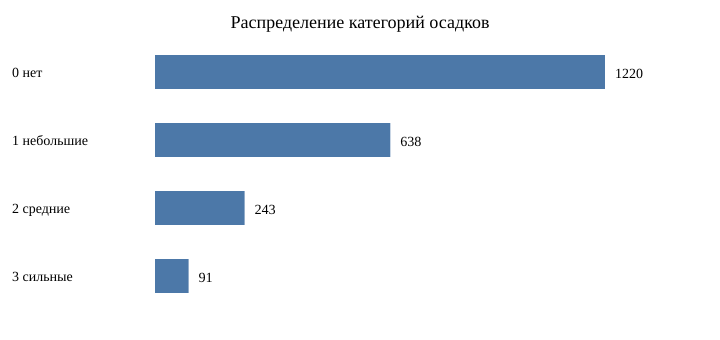

In [7]:
# SVG-график строится без внешних графических библиотек.
counts = raw.precip_category.value_counts().reindex([0,1,2,3], fill_value=0).to_numpy()
labels = ["0 нет", "1 небольшие", "2 средние", "3 сильные"]
max_count = max(counts)
bar_svg = ['<svg xmlns="http://www.w3.org/2000/svg" width="720" height="340" viewBox="0 0 720 340">', '<rect width="100%" height="100%" fill="white"/>']
bar_svg += ['<text x="360" y="28" text-anchor="middle" font-size="18">Распределение категорий осадков</text>']
for i,(lab,val) in enumerate(zip(labels,counts)):
    y=55+i*68; width=450*val/max_count
    bar_svg += [f'<text x="12" y="{y+22}" font-size="14">{lab}</text>', f'<rect x="155" y="{y}" width="{width:.1f}" height="34" fill="#4C78A8"/>', f'<text x="{165+width:.1f}" y="{y+23}" font-size="14">{val}</text>']
bar_svg += ['</svg>']
from IPython.display import SVG, display
display(SVG(''.join(bar_svg)))


## 9. Выводы

Финальный вывод формируется по сохранённым тестовым метрикам. Сравнение относится к бинарной цели, горизонту в один день и одному тестовому периоду. Логистическая регрессия — дополнительная табличная модель, поскольку среда этого запуска не содержит TensorFlow для повторного обучения исходной LSTM.


Итог: логистическая регрессия с календарными признаками и 20 лагами получила Accuracy=0.6241, F1=0.5404, ROC-AUC=0.6854. Эксперимент не подтверждает улучшение относительно исходных ARIMA/LSTM (Accuracy=0.6697, F1=0.6539); вывод об улучшении не делается.
